# Using genomic-benchmarks-data

This notebook demonstrates dataset discovery, metadata, loading, caching, and quality-control (QC) results with the full package. The full package exposes all published splits, including test data.

Install the package if it is not already available in this environment:

In [10]:
# %pip install genomic-benchmarks-data
%pip install --force-reinstall /tmp/gb-test-wheels/genomic_benchmarks_data-0.0.1-py3-none-any.whl

Processing /tmp/gb-test-wheels/genomic_benchmarks_data-0.0.1-py3-none-any.whl
  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached numpy-2.5.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached pandas-3.0.6-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached platformdirs-4.12.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached pyarrow-25.0.1-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (3.0 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (130 kB)
  Using cached kiwisolver-1.5.1-cp312-

In [6]:
from html import escape
from IPython.display import HTML, display
import genomic_benchmarks_data as gbd


def display_qc_report(path, height=900):
    """Display a standalone QC report without leaking its styles into Jupyter."""
    document = escape(path.read_text(encoding="utf-8"), quote=True)
    return HTML(
        f"<iframe srcdoc=\"{document}\" "
        f"style=\"width: 100%; height: {height}px; border: 1px solid #ddd;\""
        "></iframe>"
    )

## Discover datasets

In [2]:
collections = gbd.list_collections()
binary_datasets = gbd.list_datasets(task_type="Binary classification")

collections, binary_datasets

({'BEACON': 'https://doi.org/10.52202/079017-2949',
  'GUE_v2': 'https://doi.org/10.48550/arXiv.2306.15006',
  'OmniGenBench': 'https://doi.org/10.48550/arXiv.2505.14402',
  'genomic-benchmarks': 'https://doi.org/10.1186/s12863-023-01123-8',
  'mRNABench': 'https://doi.org/10.1101/2025.07.05.662870',
  'miRBench': 'https://doi.org/10.1093/bioinformatics/btaf233',
  'nucleotide_benchmarks': 'https://doi.org/10.1038/s41592-024-02523-z'},
 {'GUE_v2': {'core_promoter_detection_all': 'Prediction of core promoter regions (all)',
   'core_promoter_detection_notata': 'Prediction of core promoter regions (non-TATA)',
   'core_promoter_detection_tata': 'Prediction of core promoter regions (TATA)',
   'promoter_detection_300_all': 'Prediction of proximal promoter regions (300 bp, all)',
   'promoter_detection_300_notata': 'Prediction of proximal promoter regions (300 bp, non-TATA)',
   'promoter_detection_300_tata': 'Prediction of proximal promoter regions (300 bp, TATA)',
   'transcription_facto

The examples below use a small dataset that provides train, validation (`val`), and test splits.

In [5]:
COLLECTION = "BEACON"
DATASET = "CRISPROnTarget"

## Inspect metadata

In [4]:
dataset_info = gbd.get_dataset_info(COLLECTION, DATASET)
train_info = gbd.get_split_info(COLLECTION, DATASET, "train")

{
    "task_type": dataset_info["task_type"],
    "sequence_columns": dataset_info["seq_col"],
    "label_column": dataset_info["label_col"],
    "available_splits": dataset_info["splits"],
    "train_size": train_info["dataset_size"],
}

{'task_type': 'Regression',
 'sequence_columns': ['seq'],
 'label_column': 'label',
 'available_splits': ['train', 'val', 'test'],
 'train_size': 1453}

## Load data

By default, `train` and `val` contain the sequence and label columns needed for the task.

In [5]:
train = gbd.load_dataset(COLLECTION, DATASET, "train")
validation = gbd.load_dataset(COLLECTION, DATASET, "val")

{"train_columns": train.columns.tolist(), "val_columns": validation.columns.tolist()}

CRISPROnTarget_train.csv.gz: 100%|██████████| 31.4k/31.4k [00:00<00:00, 114kB/s]
CRISPROnTarget_val.csv.gz: 100%|██████████| 4.82k/4.82k [00:00<00:00, 8.66MB/s]


{'train_columns': ['seq', 'label'], 'val_columns': ['seq', 'label']}

In [6]:
train.head()

,seq,label
0,TTCACTGCGCAGCCTGGCATTGG,0.261026
1,TTCATTTACTGACTTCAGATTGG,0.088202
2,AAAGAGGTCGAAGATGTAGCGGG,0.103584
3,CAAGATTGATCAGAAAGCTGTGG,0.274124
4,TTCACTGCCAGTTCTCCGCGTGG,0.315928


Use `columns="all"` when auxiliary columns are needed.

In [7]:
train_all = gbd.load_dataset(COLLECTION, DATASET, "train", columns="all")
train_all.columns.tolist()

['id', 'row_index', 'seq', 'label']

The default `test` view starts with `id` and `row_index`, followed by the sequence and label columns. These identifiers make predictions traceable to examples.

In [8]:
test = gbd.load_dataset(COLLECTION, DATASET, "test")
test.head()

CRISPROnTarget_test.csv.gz: 100%|██████████| 9.40k/9.40k [00:00<00:00, 724kB/s]


,id,row_index,seq,label
0,BEACON:CRISPROnTarget:v1:test:0000000,0,GCAGACAAGAAGCGCAGGACAGG,0.208640
1,BEACON:CRISPROnTarget:v1:test:0000001,1,CCTTGCCTCCGCGAGCTCCGCGG,0.413518
2,BEACON:CRISPROnTarget:v1:test:0000002,2,ATCTGCCAGGCACTCAGCAATGG,0.313632
3,BEACON:CRISPROnTarget:v1:test:0000003,3,TTACGAGTTCACCTGTGTGAAGG,0.221238
4,BEACON:CRISPROnTarget:v1:test:0000004,4,CTGGCCCGTGTGAATGCCCTCGG,0.252790


## Locate a downloaded file

`download_dataset()` returns the complete cached file, regardless of the column view selected by `load_dataset()`.

In [9]:
cached_test_path = gbd.download_dataset(COLLECTION, DATASET, "test")
cached_test_path

PosixPath('/homes/ssamm10/.cache/genomic_benchmarks_data/data/BEACON/CRISPROnTarget/v1/test/079f02744eed3c92be96817ee5c73a3eeeca53112aecaba5cc09c0e18ef61be7/CRISPROnTarget_test.csv.gz')

## Explore QC results

Class QC examines individual splits. Split QC compares two splits for leakage.

In [12]:
%pip install --force-reinstall --no-deps /tmp/gb-qc-plot-build-normal/genomic_benchmarks_data-0.0.1-py3-none-any.whl

Processing /tmp/gb-qc-plot-build-normal/genomic_benchmarks_data-0.0.1-py3-none-any.whl
  Attempting uninstall: genomic-benchmarks-data
    Found existing installation: genomic-benchmarks-data 0.0.1
    Uninstalling genomic-benchmarks-data-0.0.1:
      Successfully uninstalled genomic-benchmarks-data-0.0.1
Note: you may need to restart the kernel to use updated packages.


In [1]:
import getpass
import os

os.environ["GENOMIC_BENCHMARKS_DATA_QC_ZENODO_TOKEN"] = getpass.getpass(
    "Zenodo preview token: "
)

import genomic_benchmarks_data as gbd

In [2]:
class_qc = gbd.load_qc_results("class")
split_qc = gbd.load_qc_results("split")

{
    "class_checks": gbd.list_qc_metrics("class"),
    "split_checks": gbd.list_qc_metrics("split"),
}

{'class_checks': ['Duplicate Sequences between Labels',
  'Per position nucleotide content',
  'Per position reversed nucleotide content',
  'Per sequence GC content',
  'Per sequence dinucleotide content',
  'Per sequence nucleotide content',
  'Sequence Duplications within Labels',
  'Sequence lengths',
  'Unique bases'],
 'split_checks': ['Data Leakage']}

In [3]:
passing_class_qc = gbd.filter_datasets_by_qc("class", flag="Pass")
passing_split_qc = gbd.filter_datasets_by_qc("split", flag="Pass")

{"class": passing_class_qc, "split": passing_split_qc}

{'class': {'GUE_v2': ['enhancer_promoter_interaction_GM12878',
   'enhancer_promoter_interaction_HeLa_S3',
   'epigenetic_marks_prediction_H3K14ac',
   'epigenetic_marks_prediction_H3K4me3',
   'transcription_factor_prediction_mouse_0',
   'transcription_factor_prediction_mouse_1',
   'transcription_factor_prediction_mouse_4'],
  'genomic-benchmarks': ['drosophila_enhancers_stark'],
  'miRBench': ['AGO2_CLASH_Hejret2023',
   'AGO2_eCLIP_Klimentova2022',
   'AGO2_eCLIP_Manakov2022']},
 'split': {'BEACON': ['CRISPROnTarget', 'MeanRibosomeLoading'],
  'GUE_v2': ['epigenetic_marks_prediction_H3',
   'epigenetic_marks_prediction_H3K4me3',
   'transcription_factor_prediction_mouse_0',
   'transcription_factor_prediction_mouse_2',
   'transcription_factor_prediction_mouse_4'],
  'nucleotide_benchmarks': ['promoter_tata'],
  'mRNABench': ['translation-efficiency-human',
   'translation-efficiency-mouse'],
  'OmniGenBench': ['poly_a_arabidopsis_thaliana',
   'poly_a_chlamydomonas_reinhardtii',


<Axes: title={'center': 'Class QC summary'}, xlabel='Collection', ylabel='Proportion of class-QC results'>

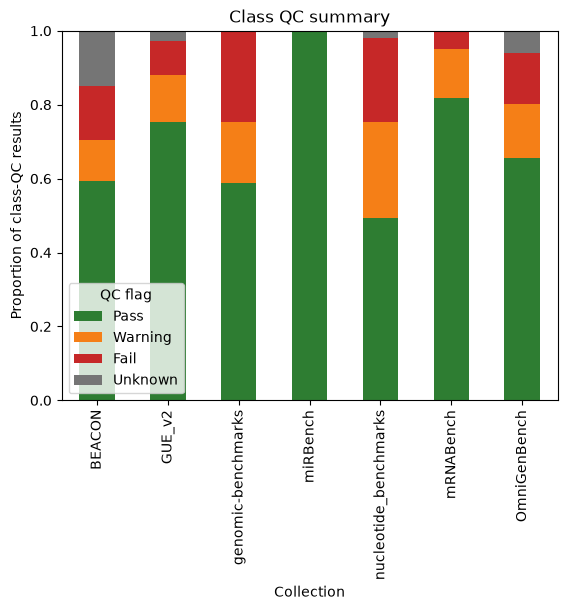

In [3]:
gbd.plot_qc_summary("class")

<Axes: title={'center': 'Class QC summary: Per sequence GC content'}, xlabel='Collection', ylabel='Proportion of datasets'>

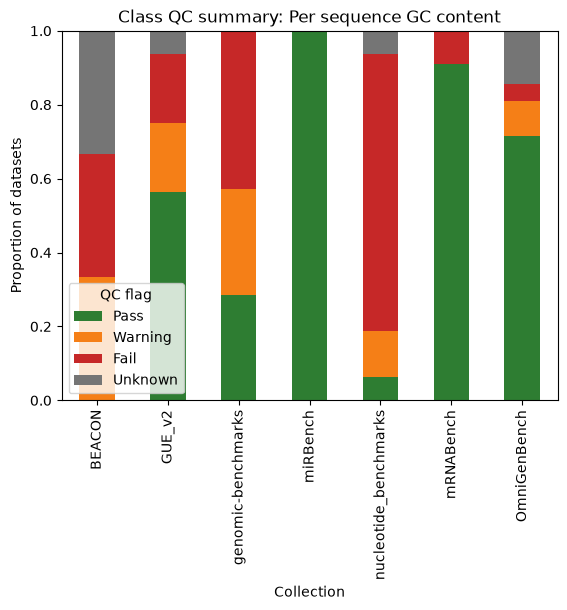

In [11]:
gbd.plot_qc_summary("class", check="Per sequence GC content")

## Open self-contained QC reports

/homes/ssamm10/GB2.0/genomic-benchmarks-data/.venv/lib/python3.12/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



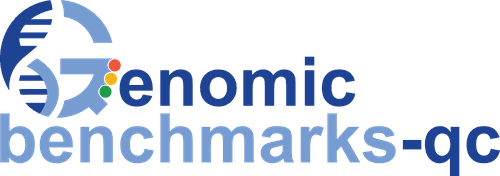

In [7]:
class_report = gbd.get_class_qc_report(
    COLLECTION, DATASET, split="train", seq_col="seq"
)
display(display_qc_report(class_report))


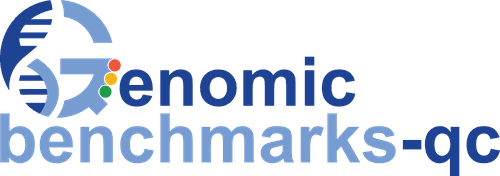

In [8]:
split_report = gbd.get_split_qc_report(
    COLLECTION, DATASET, split_a="train", split_b="test"
)
display(display_qc_report(split_report))